# Лабораторная работа №2. Вывод символов на экран дисплея

**Выполнил:** Рулев Константин Александрович  
**Вариант:** 16

**Цель:** вывести строку и фигуры, найти сумму цифр числа и сравнить размеры программ на ASM и C.

Отчёт содержит все исходники и результаты. В Google Colab выберите CPU-среду и нажмите «Среда выполнения → Выполнить все». Результаты проверены в Linux x86-64. Скриншоты сохранены из исходного запуска в Codespaces; кодовые ячейки показывают результаты повторной проверки.

## 1. Данные варианта

| Задание | Данные |
|---|---|
| 1 | Строка `TTaQgEqQJZdfGgqazcJpCDzwNgDdwpM` |
| 2 | 300 символов `;`, 25 строк по 12 символов |
| 3 | 300 символов `;`, треугольник из 24 строк |
| 4–5 | Число 2710058798; сумма цифр — 47 |

In [1]:
import random

r = random.Random(16)
alphabet = 'qwertyuioplkjhgfdsazxcvbnmQWERTYUIOPASDFGHJKLZXCVBNM'
length = r.randint(20, 40)
text = ''.join(alphabet[r.randint(0, len(alphabet) - 1)] for _ in range(length))
symbol = '!@#$%&*+:;|'[r.randint(0, 10)]
rows = r.randint(3, 30)
count = rows * (rows + 1) // 2
width = count // rows
height = count // width
number = r.randint(123432, 5645634534)
print('Строка:', text)
print('Символ:', symbol, 'Всего:', count)
print('Матрица:', height, 'строк по', width, 'символов')
print('Треугольник:', rows, 'строки')
print('Число:', number)


Строка: TTaQgEqQJZdfGgqazcJpCDzwNgDdwpM
Символ: ; Всего: 300
Матрица: 25 строк по 12 символов
Треугольник: 24 строки
Число: 2710058798


## 2. Подготовка среды

In [2]:
import os
import platform
import shutil
import subprocess
from pathlib import Path

if platform.system() != 'Linux' or platform.machine() not in ('x86_64', 'amd64'):
    raise RuntimeError('Нужна CPU-среда Linux x86-64')
if not all(shutil.which(name) for name in ('fasm', 'gcc', 'ld', 'strip', 'make')):
    prefix = [] if os.geteuid() == 0 else ['sudo']
    subprocess.run(prefix + ['apt-get', 'update', '-qq'], check=True)
    subprocess.run(prefix + ['apt-get', 'install', '-y', '-qq', 'fasm', 'gcc', 'binutils', 'make'], check=True)
base = Path('/content') if Path('/content').exists() else Path('/tmp')
work = base / 'rulev_variant16' / 'Lab_2'
work.mkdir(parents=True, exist_ok=True)
os.chdir(work)
print('Среда готова')


Среда готова


## 3. Задание 1. Обратный порядок символов

Первая и последняя буквы меняются местами. Затем указатели сдвигаются к середине строки.

### task1_reverse.asm

In [3]:
%%writefile task1_reverse.asm
format ELF64
public _start

section '.data' writable
  msg1  db "S          = "
  msg1_len = $ - msg1
  msg2  db "S reversed = "
  msg2_len = $ - msg2
  S     db "TTaQgEqQJZdfGgqazcJpCDzwNgDdwpM"
  S_len = $ - S
  nl    db 0xA

section '.text' executable
_start:

    mov rsi, msg1
    mov rdx, msg1_len
    call print
    mov rsi, S
    mov rdx, S_len + 1
    call print

    mov rsi, S
    mov rdi, S + S_len - 1
  .swap:
    cmp rsi, rdi
    jae .done
    mov al, [rsi]
    mov bl, [rdi]
    mov [rsi], bl
    mov [rdi], al
    inc rsi
    dec rdi
    jmp .swap
  .done:

    mov rsi, msg2
    mov rdx, msg2_len
    call print
    mov rsi, S
    mov rdx, S_len + 1
    call print
    call exit

section '.print' executable

print:
    push rax
    push rbx
    push rcx
    mov eax, 4
    mov ebx, 1
    mov ecx, esi
    int 0x80
    pop rcx
    pop rbx
    pop rax
    ret

section '.exit' executable
exit:
    mov eax, 1
    mov ebx, 0
    int 0x80


Writing task1_reverse.asm


## 4. Задание 2. Матрица

В память записываются 300 символов `;`. Затем выводятся 25 строк по 12 символов.

### task2_matrix.asm

In [4]:
%%writefile task2_matrix.asm
format ELF64
public _start

N = 300
M = 12
K = 25
D = ';'

section '.bss' writable
  buf db N dup (?)

section '.data' writable
  nl db 0xA

section '.text' executable
_start:

    mov rdi, buf
    mov rcx, N
    mov al, D
  .fill:
    mov [rdi], al
    inc rdi
    dec rcx
    jnz .fill

    mov rsi, buf
    mov rcx, K
  .row:
    mov rdx, M
    call print
    call newline
    add rsi, M
    dec rcx
    jnz .row
    call exit

section '.print' executable

print:
    push rax
    push rbx
    push rcx
    mov eax, 4
    mov ebx, 1
    mov ecx, esi
    int 0x80
    pop rcx
    pop rbx
    pop rax
    ret

newline:
    push rsi
    push rdx
    mov rsi, nl
    mov rdx, 1
    call print
    pop rdx
    pop rsi
    ret

section '.exit' executable
exit:
    mov eax, 1
    mov ebx, 0
    int 0x80


Writing task2_matrix.asm


## 5. Задание 3. Треугольник

В первой строке выводится один символ, во второй — два и так далее. Всего 24 строки: 1 + 2 + … + 24 = 300.

### task3_triangle.asm

In [5]:
%%writefile task3_triangle.asm
format ELF64
public _start

N = 300
D = ';'

section '.bss' writable
  buf db N dup (?)

section '.data' writable
  nl db 0xA

section '.text' executable
_start:

    mov rdi, buf
    mov rcx, N
    mov al, D
  .fill:
    mov [rdi], al
    inc rdi
    dec rcx
    jnz .fill

    mov rsi, buf
    mov rcx, 1
  .row:
    mov rdx, rcx
    call print
    call newline
    add rsi, rcx
    inc rcx
    cmp rsi, buf + N
    jb .row
    call exit

section '.print' executable

print:
    push rax
    push rbx
    push rcx
    mov eax, 4
    mov ebx, 1
    mov ecx, esi
    int 0x80
    pop rcx
    pop rbx
    pop rax
    ret

newline:
    push rsi
    push rdx
    mov rsi, nl
    mov rdx, 1
    call print
    pop rdx
    pop rsi
    ret

section '.exit' executable
exit:
    mov eax, 1
    mov ebx, 0
    int 0x80


Writing task3_triangle.asm


## 6. Задание 4. Сумма цифр

Число делится на 10. Каждый остаток прибавляется к сумме. Для 2710058798 получается 47.

### task4_digit_sum.asm

In [6]:
%%writefile task4_digit_sum.asm
format ELF64
public _start

section '.data' writable
  number dq 2710058798
  msg    db "Sum of digits of 2710058798 = "
  msg_len = $ - msg
  place  db ?

section '.text' executable
_start:
    mov rsi, msg
    mov rdx, msg_len
    call print

    mov rax, [number]
    mov rcx, 10
    xor rbx, rbx
  .digits:
    xor rdx, rdx
    div rcx
    add rbx, rdx
    test rax, rax
    jnz .digits

    mov rax, rbx
    xor rbx, rbx
  .push:
    xor rdx, rdx
    div rcx
    add rdx, '0'
    push rdx
    inc rbx
    test rax, rax
    jnz .push
  .pop:
    pop rax
    call print_symb
    dec rbx
    jnz .pop
    mov rax, 0xA
    call print_symb
    call exit

section '.print' executable

print:
    push rax
    push rbx
    push rcx
    mov eax, 4
    mov ebx, 1
    mov ecx, esi
    int 0x80
    pop rcx
    pop rbx
    pop rax
    ret

print_symb:
    push rbx
    push rcx
    push rdx
    push rax
    mov [place], al
    mov eax, 4
    mov ebx, 1
    mov ecx, place
    mov edx, 1
    int 0x80
    pop rax
    pop rdx
    pop rcx
    pop rbx
    ret

section '.exit' executable
exit:
    mov eax, 1
    mov ebx, 0
    int 0x80


Writing task4_digit_sum.asm


## 7. Задание 5. Программа на C

Используется тот же способ: складываются остатки от деления на 10. Для уменьшения C-программы включаются ключи `-Os -s`, для ASM применяется `strip`.

### task5_digit_sum.c

In [7]:
%%writefile task5_digit_sum.c
#include <stdio.h>

int main(void)
{
    unsigned long n = 2710058798UL;
    unsigned int sum = 0;
    while (n) {
        sum += n % 10;
        n /= 10;
    }
    printf("Sum of digits of 2710058798 = %u\n", sum);
    return 0;
}


Writing task5_digit_sum.c


## 8. Сборка

### Makefile

In [8]:
%%writefile Makefile
.PHONY: all check clean

all: build/task1_reverse build/task2_matrix build/task3_triangle build/task4_digit_sum build/task4_digit_sum_stripped build/task5_digit_sum build/task5_digit_sum_Os

build:
	mkdir -p build

build/%.o: %.asm | build
	fasm $< $@

build/task1_reverse build/task2_matrix build/task3_triangle build/task4_digit_sum: build/%: build/%.o
	ld -z noexecstack -o $@ $<

build/task4_digit_sum_stripped: build/task4_digit_sum
	strip -o $@ $<

build/task5_digit_sum: task5_digit_sum.c | build
	gcc -std=c11 -Wall -Wextra -Werror -O0 $< -o $@

build/task5_digit_sum_Os: task5_digit_sum.c | build
	gcc -std=c11 -Wall -Wextra -Werror -Os -s $< -o $@

check: all
	python3 check.py

clean:
	rm -rf build


Writing Makefile


In [9]:
%%bash
set -e
make all


mkdir -p build
fasm task1_reverse.asm build/task1_reverse.o
flat assembler  version 1.73.32  (16384 kilobytes memory)
3 passes, 1272 bytes.
ld -z noexecstack -o build/task1_reverse build/task1_reverse.o
fasm task2_matrix.asm build/task2_matrix.o
flat assembler  version 1.73.32  (16384 kilobytes memory)
3 passes, 1224 bytes.
ld -z noexecstack -o build/task2_matrix build/task2_matrix.o
fasm task3_triangle.asm build/task3_triangle.o
flat assembler  version 1.73.32  (16384 kilobytes memory)
3 passes, 1248 bytes.
ld -z noexecstack -o build/task3_triangle build/task3_triangle.o
fasm task4_digit_sum.asm build/task4_digit_sum.o
flat assembler  version 1.73.32  (16384 kilobytes memory)
3 passes, 1256 bytes.
ld -z noexecstack -o build/task4_digit_sum build/task4_digit_sum.o
strip -o build/task4_digit_sum_stripped build/task4_digit_sum
gcc -std=c11 -Wall -Wextra -Werror -O0 task5_digit_sum.c -o build/task5_digit_sum
gcc -std=c11 -Wall -Wextra -Werror -Os -s task5_digit_sum.c -o build/task5_digit_

## 9. Результаты

### Задание 1

In [10]:
%%bash
set -e
./build/task1_reverse


S          = TTaQgEqQJZdfGgqazcJpCDzwNgDdwpM
S reversed = MpwdDgNwzDCpJczaqgGfdZJQqEgQaTT


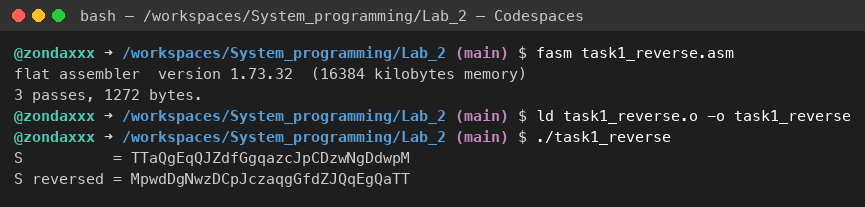

### Задание 2

In [11]:
%%bash
set -e
./build/task2_matrix


;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;


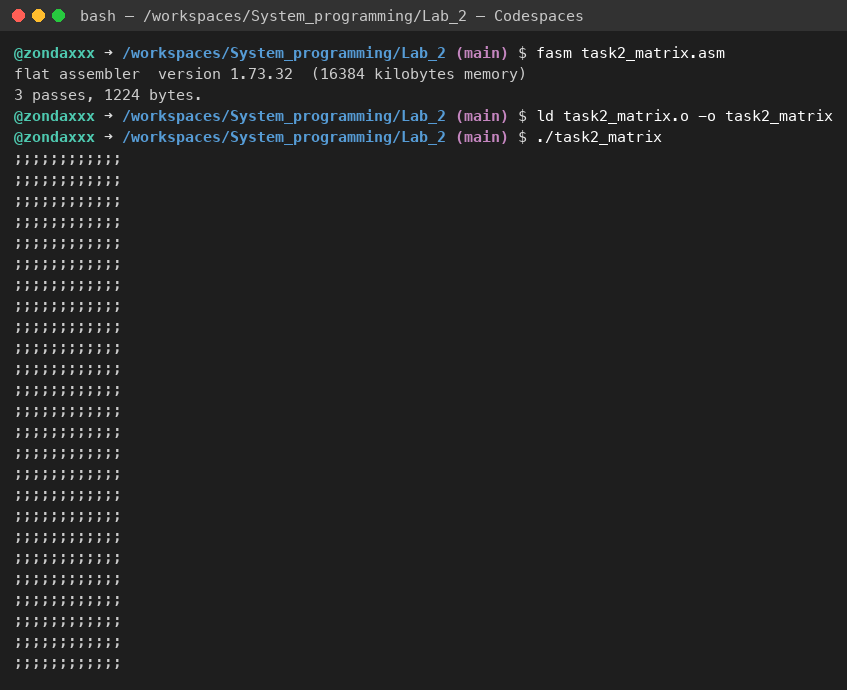

### Задание 3

In [12]:
%%bash
set -e
./build/task3_triangle


;
;;
;;;
;;;;
;;;;;
;;;;;;
;;;;;;;
;;;;;;;;
;;;;;;;;;
;;;;;;;;;;
;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;;
;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;;;;;;;;;;


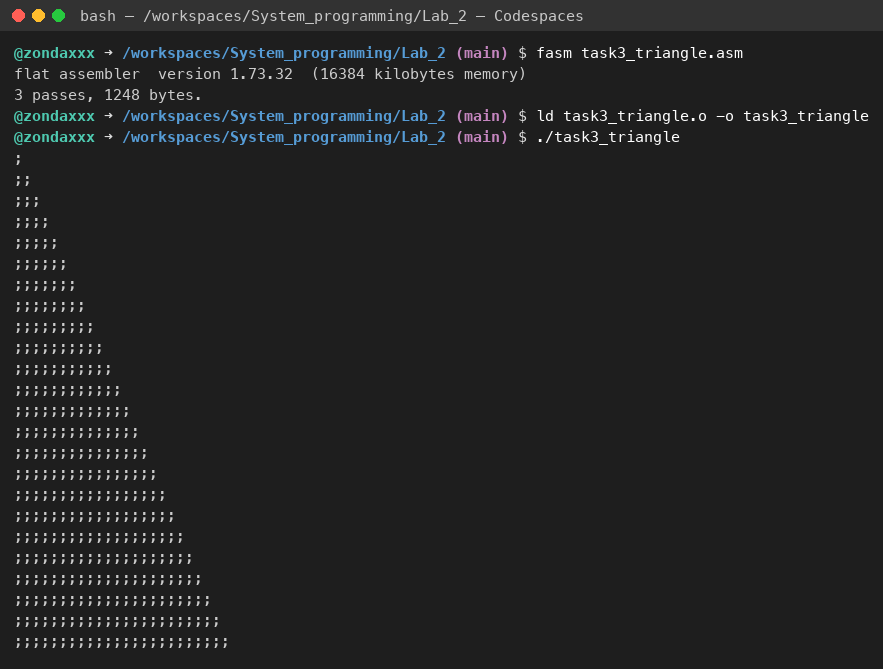

### Задания 4 и 5

Все четыре сборки должны вывести одинаковую сумму.

In [13]:
for name in ['task4_digit_sum', 'task4_digit_sum_stripped', 'task5_digit_sum', 'task5_digit_sum_Os']:
    result = subprocess.run([str(Path('build') / name)], capture_output=True, text=True, check=True)
    print(name + ': ' + result.stdout.strip())


task4_digit_sum: Sum of digits of 2710058798 = 47
task4_digit_sum_stripped: Sum of digits of 2710058798 = 47
task5_digit_sum: Sum of digits of 2710058798 = 47
task5_digit_sum_Os: Sum of digits of 2710058798 = 47


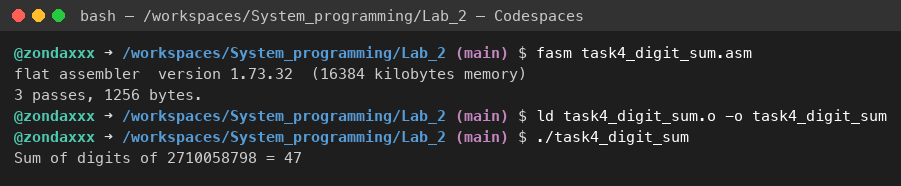

## 10. Сравнение размеров

Таблица показывает размеры файлов, полученных при текущем запуске. При другой версии компилятора размеры могут отличаться.

In [14]:
from IPython.display import display, Markdown

versions = [
    ('ASM', 'fasm + ld', 'task4_digit_sum'),
    ('ASM', 'После strip', 'task4_digit_sum_stripped'),
    ('C', 'gcc -O0', 'task5_digit_sum'),
    ('C', 'gcc -Os -s', 'task5_digit_sum_Os'),
]
table = '| Язык | Сборка | Размер, байт |\n|---|---|---:|\n'
for language, mode, name in versions:
    table += f'| {language} | {mode} | {(Path("build") / name).stat().st_size} |\n'
display(Markdown(table))


| Язык | Сборка | Размер, байт |
|---|---|---:|
| ASM | fasm + ld | 8944 |
| ASM | После strip | 8656 |
| C | gcc -O0 | 15976 |
| C | gcc -Os -s | 14472 |


## 11. Проверка

Проверяются разворот строки, размеры матрицы и треугольника, сумма цифр и уменьшение файлов.

### check.py

In [15]:
%%writefile check.py
from pathlib import Path
import subprocess


def run(name):
    result = subprocess.run([str(Path('build') / name)], capture_output=True,
                            text=True, timeout=5, check=True)
    assert not result.stderr, result.stderr
    return result.stdout


text = 'TTaQgEqQJZdfGgqazcJpCDzwNgDdwpM'
assert run('task1_reverse') == f'S          = {text}\nS reversed = {text[::-1]}\n'
print('Задание 1: строка выведена в обратном порядке.')

matrix = run('task2_matrix')
assert matrix == (';' * 12 + '\n') * 25
assert matrix.count(';') == 300
print('Задание 2: 25 строк по 12 символов, всего 300.')

triangle = run('task3_triangle')
assert triangle == ''.join(';' * n + '\n' for n in range(1, 25))
assert triangle.count(';') == 300
print('Задание 3: 24 строки, всего 300 символов.')

expected = sum(map(int, str(2710058798)))
for name in ['task4_digit_sum', 'task4_digit_sum_stripped',
             'task5_digit_sum', 'task5_digit_sum_Os']:
    assert run(name) == f'Sum of digits of 2710058798 = {expected}\n'
print('Задания 4 и 5: сумма цифр равна 47 во всех четырёх сборках.')

assert Path('build/task4_digit_sum_stripped').stat().st_size < Path('build/task4_digit_sum').stat().st_size
assert Path('build/task5_digit_sum_Os').stat().st_size < Path('build/task5_digit_sum').stat().st_size
print('Размеры программ на ASM и C уменьшены. Все 7 запусков прошли проверку.')


Writing check.py


In [16]:
%%bash
set -e
make check


python3 check.py
Задание 1: строка выведена в обратном порядке.
Задание 2: 25 строк по 12 символов, всего 300.
Задание 3: 24 строки, всего 300 символов.
Задания 4 и 5: сумма цифр равна 47 во всех четырёх сборках.
Размеры программ на ASM и C уменьшены. Все 7 запусков прошли проверку.


## Вывод

Строка выведена в обратном порядке. Матрица и треугольник содержат по 300 символов. Программы на ASM и C дают сумму цифр 47. Размеры файлов уменьшены без изменения результата.